# Lung Cancer Image Classification using VGG16

This notebook is prepared for **Jupyter Notebook in VS Code**. It uses transfer learning with VGG16 to classify images into three classes.

Expected dataset layout:
```text
lung_cancer_dataset/
├── Benign/
├── Malignant/
└── Normal/
```

Update the dataset path below to the folder containing the class subfolders. This is an educational project, not a medical diagnostic tool.


## 1. Install dependencies

Run once in the selected notebook kernel. Alternatively, install from `requirements.txt` in the VS Code terminal.


In [8]:
%pip install "tensorflow>=2.15,<2.19" "numpy>=1.24" "matplotlib>=3.7" "seaborn>=0.12" "scikit-learn>=1.3"


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: C:\Users\Rutvik\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## 2. Import libraries and configure paths

In [9]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

print("Import Successful")
SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10
DATASET_DIR = Path("lung_cancer_dataset")  # Change if your dataset is elsewhere
OUTPUT_DIR = Path("results")
MODEL_PATH = Path("lung_cancer_vgg16_model.keras")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

tf.random.set_seed(SEED)
np.random.seed(SEED)
print("TensorFlow version:", tf.__version__)
print("Working directory:", Path.cwd())
print("Dataset directory:", DATASET_DIR.resolve())


Import Successful
TensorFlow version: 2.18.1
Working directory: c:\Users\Rutvik\Downloads\PROJECT_LUNGS_Jupyter_VSCode
Dataset directory: C:\Users\Rutvik\Downloads\PROJECT_LUNGS_Jupyter_VSCode\lung_cancer_dataset


## 3. Check the dataset folder structure

The dataset directory must contain exactly three class folders. If your dataset is nested inside another folder, update `DATASET_DIR` above.


In [10]:
if not DATASET_DIR.exists():
    candidates = [
        Path("The IQ-OTHNCCD lung cancer dataset"),
        Path("data"),
        Path("dataset"),
        Path("lung_cancer_dataset/The IQ-OTHNCCD lung cancer dataset"),
    ]
    found = next((p for p in candidates if p.exists()), None)
    if found is not None:
        DATASET_DIR = found
        print("Using detected dataset folder:", DATASET_DIR.resolve())
    else:
        raise FileNotFoundError(
            "Dataset folder not found. Set DATASET_DIR to the folder containing the class subfolders."
        )

class_dirs = sorted([p for p in DATASET_DIR.iterdir() if p.is_dir()])
class_names = [p.name for p in class_dirs]
print("Classes found:", class_names)
if len(class_names) != 3:
    raise ValueError(f"Expected exactly 3 class folders, but found {len(class_names)}: {class_names}")

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}
for class_dir in class_dirs:
    count = sum(1 for p in class_dir.rglob("*") if p.is_file() and p.suffix.lower() in valid_extensions)
    print(f"{class_dir.name}: {count} images")


Classes found: ['Bengin cases', 'Malignant cases', 'Normal cases']
Bengin cases: 120 images
Malignant cases: 561 images
Normal cases: 416 images


## 4. Load and preprocess images

The data is split into 80% training and 20% validation. Images are resized to 224 × 224 pixels.


In [11]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
)

class_names = train_ds.class_names
print("Class index mapping:", {i: name for i, name in enumerate(class_names)})
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)


Found 1097 files belonging to 3 classes.
Using 878 files for training.
Found 1097 files belonging to 3 classes.
Using 219 files for validation.
Class index mapping: {0: 'Bengin cases', 1: 'Malignant cases', 2: 'Normal cases'}


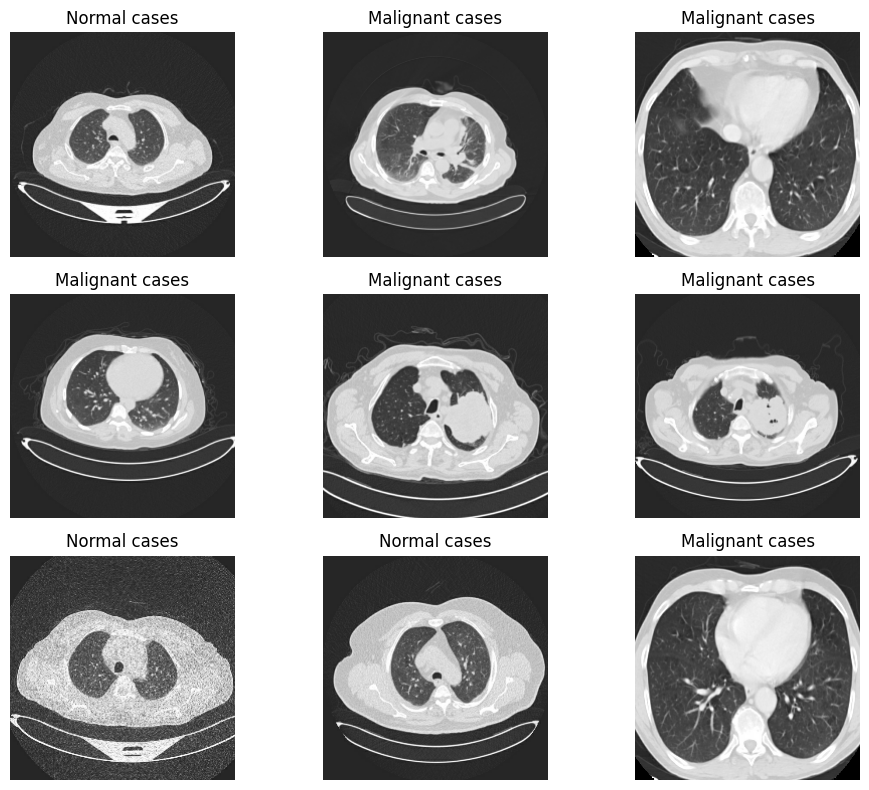

In [12]:
# Preview sample images
plt.figure(figsize=(10, 8))
for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i].numpy())])
        plt.axis("off")
plt.tight_layout()
plt.show()


## 5. Build the VGG16 transfer-learning model

The pretrained VGG16 convolutional base is frozen, and a custom classification head is trained for the three classes.


In [13]:
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3),
)
base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)),
    layers.Rescaling(1.0 / 255),
    base_model,
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,138,243 (80.64 MB)

 Trainable params: 6,423,555 (24.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

## 6. Train the model

The best checkpoint is saved based on validation loss. Training may take some time depending on your hardware and dataset size.


In [14]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1,
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)
print("Best model checkpoint path:", MODEL_PATH.resolve())


Epoch 1/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5067 - loss: 3.7662
Epoch 1: val_loss improved from inf to 0.42563, saving model to lung_cancer_vgg16_model.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 102s 4s/step - accuracy: 0.5103 - loss: 3.7172 - val_accuracy: 0.8539 - val_loss: 0.4256
Epoch 2/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8307 - loss: 0.4090
Epoch 2: val_loss improved from 0.42563 to 0.31697, saving model to lung_cancer_vgg16_model.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 99s 4s/step - accuracy: 0.8311 - loss: 0.4082 - val_accuracy: 0.8858 - val_loss: 0.3170
Epoch 3/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8550 - loss: 0.3512
Epoch 3: val_loss improved from 0.31697 to 0.27331, saving model to lung_cancer_vgg16_model.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 99s 4s/step - accuracy: 0.8554 - loss: 0.3503 - val_accuracy: 0.8858 - val_loss: 0.2733
Epoch 4/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8651 - loss: 0.2867
Epoch 4: val_loss improved from 

## 7. Plot training and validation accuracy/loss

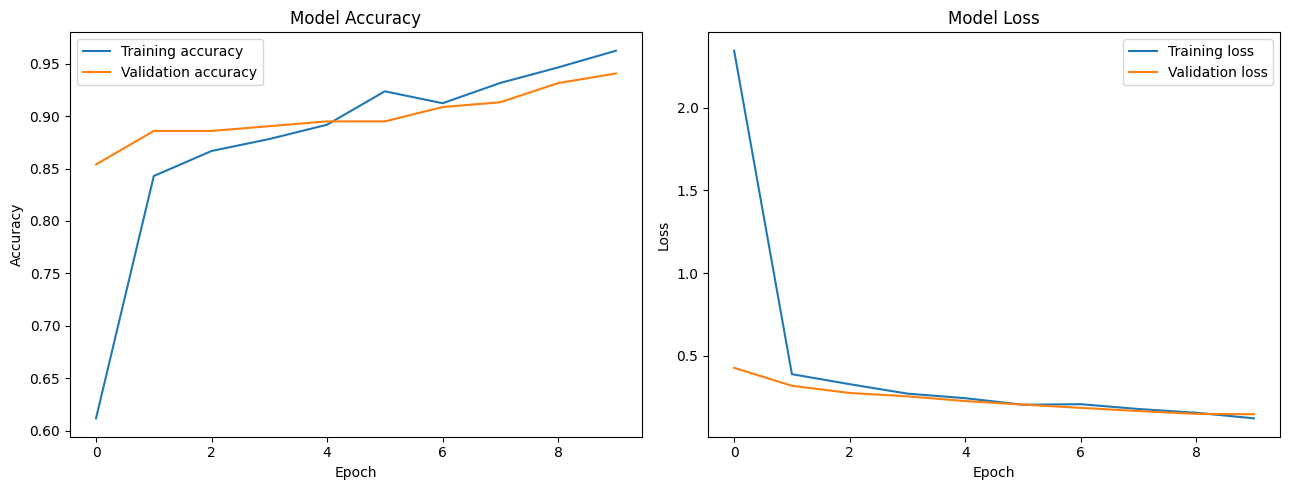

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_history.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. Evaluate the model

The metrics below are calculated on the validation subset. For a final research evaluation, use a separate held-out test set if one is available.


In [16]:
val_loss, val_accuracy = model.evaluate(val_ds, verbose=1)
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy:.4f}")

y_true = np.concatenate([labels.numpy() for _, labels in val_ds])
probabilities = model.predict(val_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

print("\nClassification report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0,
))


7/7 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - accuracy: 0.9492 - loss: 0.1208
Validation loss: 0.1445
Validation accuracy: 0.9406
7/7 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step

Classification report:

                 precision    recall  f1-score   support

   Bengin cases       0.20      0.10      0.13        21
Malignant cases       0.48      0.48      0.48       107
   Normal cases       0.41      0.46      0.44        91

       accuracy                           0.43       219
      macro avg       0.36      0.34      0.35       219
   weighted avg       0.42      0.43      0.43       219



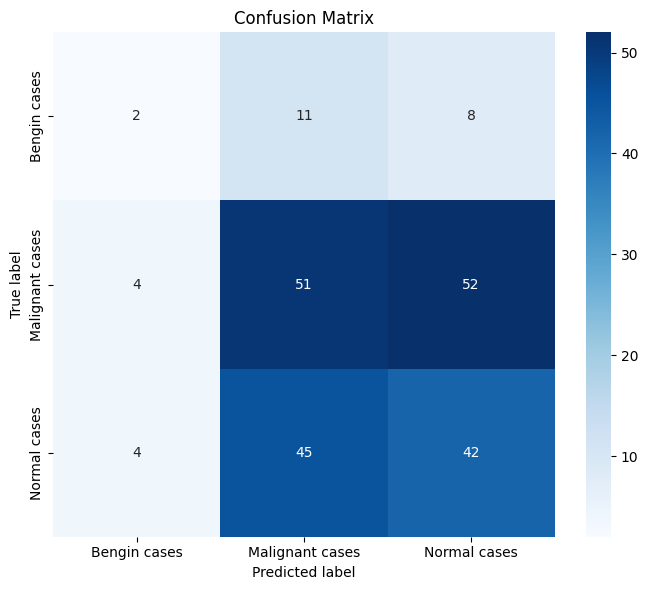

In [17]:
cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()


## 9. Predict a single image



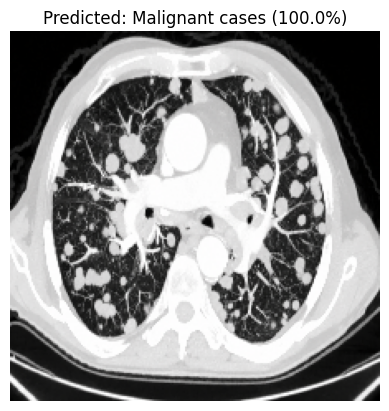

Class probabilities:
Bengin cases: 0.00%
Malignant cases: 100.00%
Normal cases: 0.00%


In [18]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

IMAGE_PATH = os.path.join(os.getcwd(), "sample_image.png")

if os.path.exists(IMAGE_PATH):
    image = tf.keras.utils.load_img(
        IMAGE_PATH,
        target_size=IMAGE_SIZE
    )

    image_array = tf.keras.utils.img_to_array(image)
    image_batch = np.expand_dims(image_array, axis=0)

    prediction = model.predict(image_batch, verbose=0)[0]
    predicted_index = int(np.argmax(prediction))

    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Predicted: {class_names[predicted_index]} "
        f"({prediction[predicted_index]:.1%})"
    )
    plt.show()

    print("Class probabilities:")
    for name, score in zip(class_names, prediction):
        print(f"{name}: {score:.2%}")
else:
    print("Image not found:", IMAGE_PATH)
    print("Make sure sample_image.png is in the project folder.")

## 10. Saved outputs

After successful training, the notebook saves:
- `lung_cancer_vgg16_model.keras` — best model checkpoint
- `results/training_history.png` — accuracy and loss plots
- `results/confusion_matrix.png` — validation confusion matrix

In VS Code, select your intended Python interpreter/kernel before running the cells. Python 3.10 (64-bit) is a suitable choice for the dependency range in this notebook.
